# Labjournaal BM
## General
**Name:**  Youri Israel en Pim van der Heijden

**Title of the experiment:** Bepaling van de constante van Boltzmann  

**Starting date:**  12/11/2026

**Expected enddate:**  23/11/2026

**Partner:**  Youri Israel/Pim van der Heijden

**Goal of the experiment:** Met de $(I,V)$-karakteristiek van een silicium diode de constante van Boltzmann $k_B$ bepalen.  
**Research question:** Welke waarde van $k_B$ (met onzekerheid) volgt uit de $(I,V)$-karakteristiek van de diode?  
**Expectations or Hypothesis:** De stroom neemt exponentieel toe met de spanning (een rechte lijn in een semi-log plot). Verwacht wordt dat $k_B$ binnen de onzekerheid gelijk is aan de tabelwaarde $1{,}380649\cdot10^{-23}\,\mathrm{J/K}$.  
**Desired accuracy:** Een onzekerheid in $k_B$ van ongeveer 5 %. Die wordt vooral bepaald door de onzekerheid in $n$.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import curve_fit
from IPython.display import Markdown, display


# Preparation

**Assignments:**

---
### Opdracht 1 – Nauwkeurigheid en gevoeligheid van een DMM

**a) Nauwkeurigheid.** Specificatie ($10\,\mathrm{V}$-bereik): $\pm(0{,}0015\,\%$ van de aflezing $+\ 0{,}0004\,\%$ van het bereik$)$. Aflezing: $5{,}00000\,\mathrm{V}$.

- aflezing: $0{,}0015\,\% \cdot 5{,}00000\,\mathrm{V} = 75\,\mu\mathrm{V}$
- bereik: $0{,}0004\,\% \cdot 10\,\mathrm{V} = 40\,\mu\mathrm{V}$
- totaal: $75 + 40 = 115\,\mu\mathrm{V}$

Resultaat: $U = 5{,}00000 \pm 0{,}00012\,\mathrm{V}$. De laatste twee cijfers op het display zijn dus niet betrouwbaar.

**b) Gevoeligheid.** Een $4\frac{1}{2}$ digit DMM heeft 20000 tellen. Op het $200\,\mathrm{mV}$-bereik is één tel $200\,\mathrm{mV}/20000 = 10\,\mu\mathrm{V}$. De gevoeligheid is dus $10\,\mu\mathrm{V}$. Bij $9\,\mathrm{mV}$ is dat een relatieve resolutie van ca. $0{,}11\,\%$.

---
### Opdracht 2 – Waarom niet direct meten aan de diode?

**Stroom direct meten werkt slecht:**

- De stroom verandert tussen $0{,}1$ en $0{,}6\,\mathrm{V}$ met ca. 5 decades. Je moet steeds van bereik wisselen, en de kleinste stromen (ca. nA) zijn te klein voor een gewone DMM.
- Een stroommeter heeft een eigen weerstand $R_i$ ($100\,\Omega$–$1\,\mathrm{k}\Omega$ in de laagste bereiken). Bij $U_D \approx 0{,}6\,\mathrm{V}$ is de diodeweerstand maar enkele honderden $\Omega$, dus $R_i$ is even groot als $R_D$. De meter verstoort dan de schakeling en de stroom wordt kleiner.

---
### Opdracht 3 – Spanningsdeler $330\,\Omega$ en $1000\,\Omega$, $P_{max} = 1\,\mathrm{W}$

- Maximale stroom uit $P = I^2R$: $I_{max} = \sqrt{P/R}$
  - $330\,\Omega$: $\sqrt{1/330} = 55{,}0\,\mathrm{mA}$
  - $1000\,\Omega$: $\sqrt{1/1000} = 31{,}6\,\mathrm{mA}$
- In serie loopt door beide dezelfde stroom, dus de kleinste limiet telt: $I = 31{,}6\,\mathrm{mA}$. Dan is $U_{max} = 0{,}0316 \cdot 1330 \approx 42\,\mathrm{V}$.
- Bij $20\,\mathrm{V}$: $I = 20/1330 = 15{,}04\,\mathrm{mA}$
  - $U_{330} = 15{,}04\,\mathrm{mA} \cdot 330\,\Omega = 4{,}96\,\mathrm{V}$
  - $U_{1000} = 15{,}04\,\mathrm{mA} \cdot 1000\,\Omega = 15{,}04\,\mathrm{V}$ (som $= 20{,}00\,\mathrm{V}$, klopt)

---
### Opdracht 4 – Basisopstelling (diode en $R_1$ in serie, twee spanningsmeters)

- **Spanning over de diode:** de ene voltmeter meet de bronspanning $U_{bron}$, de andere de spanning over $R_1$. Dus $U_D = U_{bron} - U_{R_1}$.
- **Stroom door de diode:** $R_1$ staat in serie met de diode, dus $I_D = U_{R_1}/R_1$. De stroom volgt dus uit een spanningsmeting, zonder stroommeter.
- **Onzekerheden:**

$$u(U_D) = \sqrt{u(U_{bron})^2 + u(U_{R_1})^2} \qquad
{u(I_D)}= {I_D}\sqrt{\left(\frac{u(U_{R_1})}{U_{R_1}}\right)^2 + \left(\frac{u(R_1)}{R_1}\right)^2}$$


---
### Opdracht 5 – Tweede spanningsdeler ($R_2$, $R_3$)


- **Afleiding.** Parallel: $R_p = \dfrac{R_3 (R_1 + R_D)}{R_3 + R_1 + R_D}$. Met $R_2$ als deler geeft dat
$$U = \frac{R_p}{R_2 + R_p}\, U_{bron}.$$
  Als $R_3 \ll R_1 + R_D$, dan is $R_p \approx R_3$ en dus
$$U = \frac{R_3}{R_2 + R_3}\, U_{bron}.$$
- **Voorwaarde $R_3 \ll R_1 + R_D$.** Dan is de stroom door de diodetak veel kleiner dan die door $R_3$, en belast de diodetak de deler niet.
- **Extra stap voor $U_D$.** $U$ staat over $R_1$ én de diode samen, dus
$$U_D = U - U_{R_1} = \frac{R_3}{R_2 + R_3}\, U_{bron} - U_{R_1}.$$

---
### Opdracht 6 – Python-script en onzekerheid in $k_B$

Het script staat in de code-cellen hieronder.

$$u(k_B) = |k_B|\sqrt{\left(\frac{u(b)}{b}\right)^2 + \left(\frac{u(n)}{n}\right)^2 + \left(\frac{u(T)}{T}\right)^2}.$$

**Method:** Diode en $R_1$ in serie, met twee spanningsmeters. Een tweede spanningsdeler ($R_2$, $R_3$) maakt een stabiele lage spanning. 

**Theory:** $I_D(U_D) = I_0\left(e^{\,b\,U_D} - 1\right)$ met $b = -\dfrac{q}{n k_B T}$, dus $k_B = -\dfrac{q}{b\,n\,T}$. Hier is $q = -1{,}602\cdot10^{-19}\,\mathrm{C}$ (lading van het elektron), zodat $b > 0$.  
**Independent variable:** $U_{bron}$ (en daarmee $U_D$)  
**Dependent variable:** $I_D$  
**Controlled variables:** temperatuur $T$, weerstanden $R_1$, $R_2$, $R_3$, DMM-bereiken  
**Measurement instruments & Settings:** 3½ digit DMM (bronspanning), 5½ digit DMM (spanning over $R_1$ en de weerstandsmetingen)  
**Procedure:**
1. Meet $R_1$, $R_2$ en $R_3$ met de 5½ digit DMM.
2. Bouw de schakeling op: bron → $R_2$, met $R_3$ parallel aan ($R_1$ + diode).
3. Verhoog $U_{bron}$ stapsgewijs. Noteer bij elke stap $U_{bron}$, $U_{R_1}$ en de ingestelde meetbereiken.

**Setup (drawing or picture):**
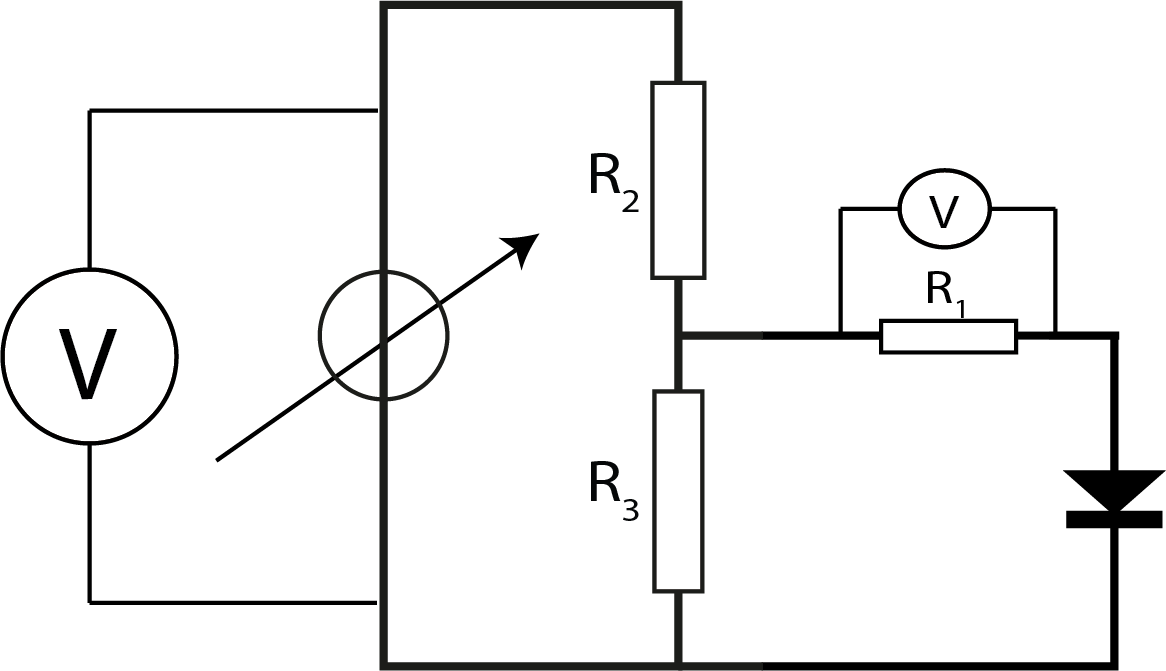
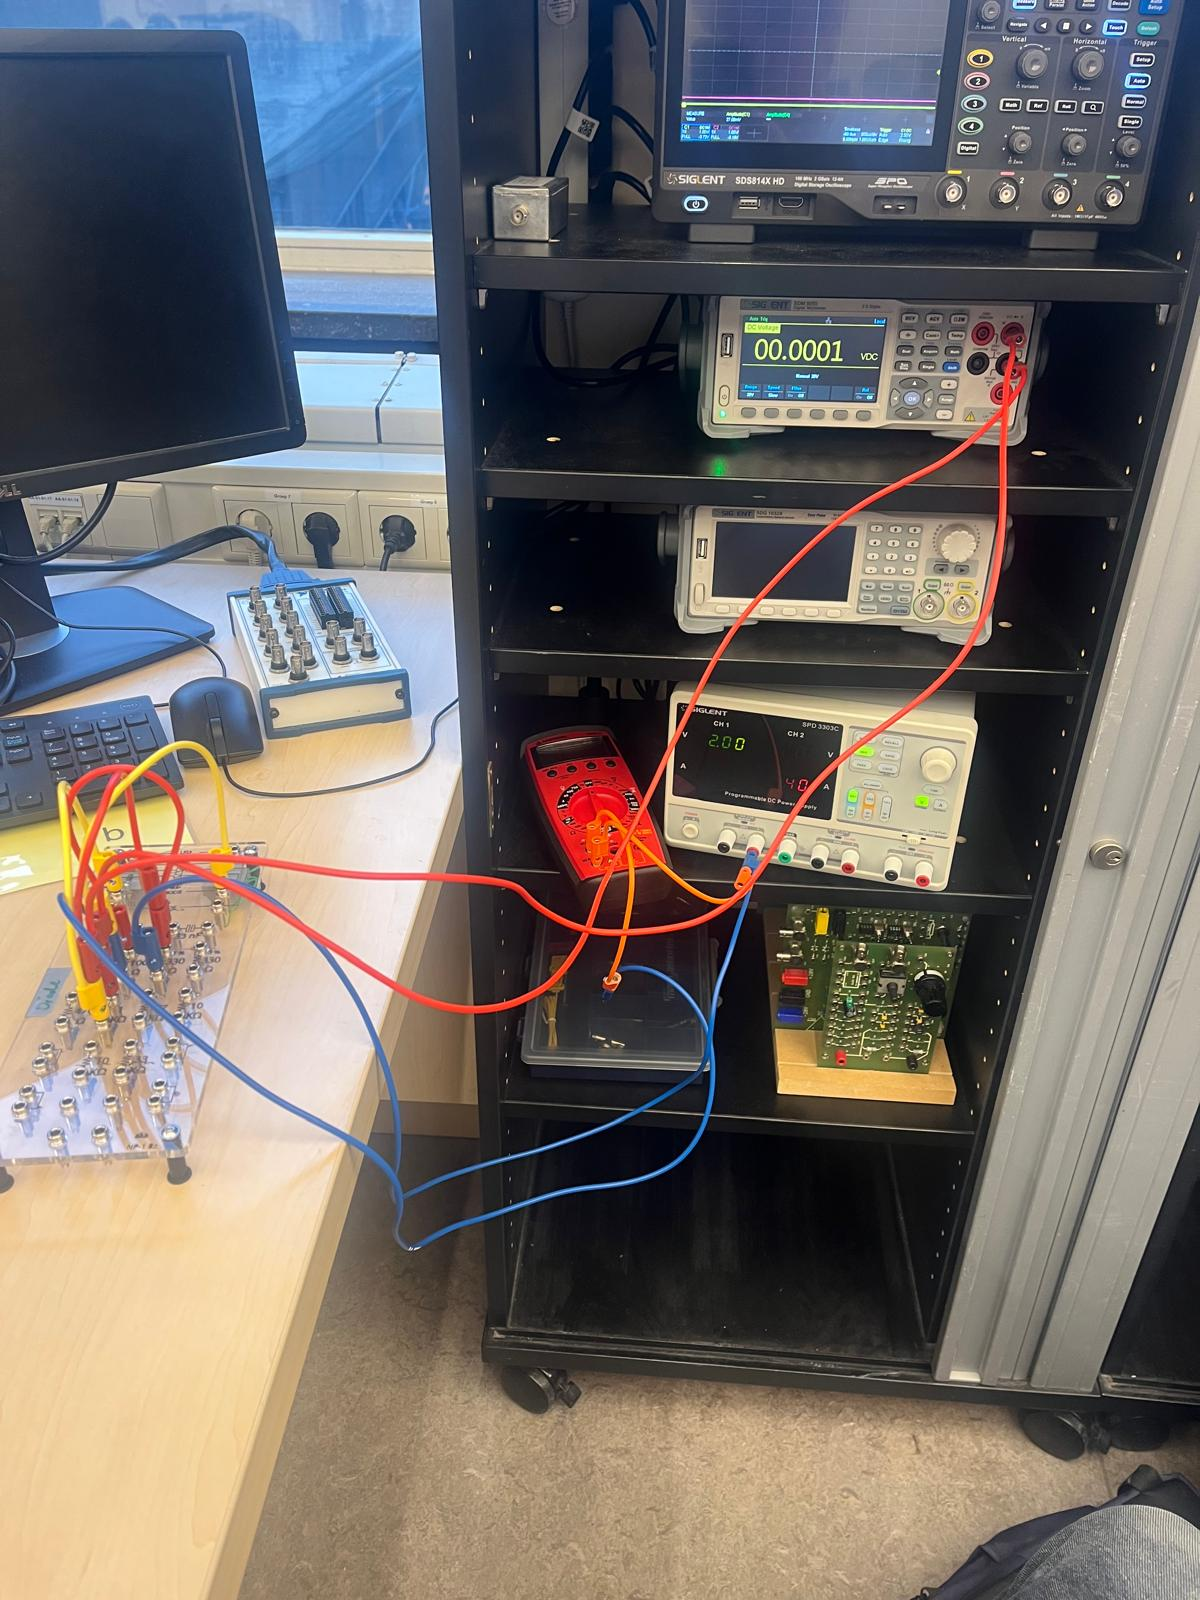
**Notes:**  
**About accuracy:** De onzekerheid van elke spanning komt uit de DMM-specificatie (% van aflezing + % van bereik + tellen). Die van $R_1$, $R_2$, $R_3$ komt uit de weerstandsmetingen.

In [2]:
# DMM-specificatie als (% van aflezing, % van bereik, aantal tellen, tellen op het volle bereik)
#Deze code is achteraf geschreven, we hadden geen toegang meer tot de meters en wisten niet de specificaties, dus hebben een schatting gemaakt zodat we wel de berekeningen konden uitvoeren

SPEC_35 = (0.5,  0.0,   3, 4000)     # 3 3/4 digit
SPEC_55 = (0.015, 0.003, 0, 200000) # Siglent SDM3055, 5 1/2 digit

def u_dmm(aflezing, bereik, spec):
    # Onzekerheid van een DMM-meting   
    pct_aflezing, pct_bereik, tellen, max_tellen = spec
    een_tel = bereik / max_tellen
   
    return pct_aflezing/100*aflezing + pct_bereik/100*bereik + tellen*een_tel

def lijn(U, b, lnI0):
    # ln(I_D) = b*U_D + ln(I0), zie vergelijking (4)
    return b*U + lnI0

# Execution

In [3]:
#ruwe data
U_bron   = np.array([2.634,2.794,2.943,3.093,3.243,3.393,3.542,3.692,3.843, 3.992,4.14,4.29,4.44,4.59,4.74,4.89,5.04,5.19,5.33])
rang_bron = np.array([4,4,4,4,4,4,4,4,4,4,4,40,40,40,40,40,40,40,40])
U_R1     = np.array([0.09961, 0.12464,0.14927, 0.17499,0.20144,0.22858,0.25610,0.28412, 0.31259,0.34139,0.37033,0.39955,0.42912,0.45863,0.48854,0.518460,0.54860,0.57874,0.60911])
rang_R1   = np.array([2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2])

# Weerstanden uit de weerstandsmetingen
R1, u_R1 = 997.3, 0.01  
R2, u_R2 = 328.72, 0.01    
R3, u_R3 = 100.079, 0.001  

q = -1.602176634e-19       # lading elektron [C]
T, u_T = 293.15, 1.0       # temperatuur [K],
n, u_n = 2.0, 0.1          # idealiteitsfactor Si (uit de opdrachttekst)

**Observations:**  
**Notes:**  

# Processing
**Description of processing of raw data into scientific evidence:**  
Uit $U_{bron}$ en $U_{R_1}$ worden $U_D$ en $I_D$ uitgerekend (opdracht 4 en 5), inclusief onzekerheden. **In de semi-log plot liggen de meetpunten (van $U_D \approx 0{,}51$ tot $0{,}64\,\mathrm{V}$) bijna op een rechte lijn. Dat komt doordat de exponent in dit gebied groot is: met $b \approx 15\,\mathrm{V^{-1}}$ geldt $e^{bU_D}  \approx 3000 \gg 1$. De $-1$ in de diodevergelijking mag je dan weglaten:

$$I_D = I_0\, e^{bU_D}, \qquad b = \frac{-q}{n k_B T} \tag{3}$$

Neem je van beide kanten de natuurlijke logaritme, dan krijg je

$$\ln I_D = b\,U_D + \ln I_0 \tag{4}$$

Dit is een rechte lijn $y = c\,x + d$, met helling $c = b$ en snijpunt $d = \ln I_0$. Uit de helling volgt

$$k_B = \frac{-q}{b\,n\,T}$$

**Onzekerheid in $\ln I_D$.** Voor de fit moeten de onzekerheden ook naar $\ln I_D$ worden omgerekend:

- uit $I_D$: $u(\ln I_D) = u(I_D)/I_D$
- uit $U_D$: een fout $u(U_D)$ verschuift het punt langs de lijn, wat overeenkomt met $b\,u(U_D)$ in $\ln I_D$

Samen geeft dat $u_{tot} = \sqrt{\left(u(I_D)/I_D\right)^2 + \left(b\,u(U_D)\right)^2}$.

In [4]:
# Bewerkte data en onzekerheden
u_Ubron = u_dmm(U_bron, rang_bron, SPEC_35)
u_UR1   = u_dmm(U_R1,   rang_R1,   SPEC_55)

deler = R3/(R2+R3)
U_diodetak = U_bron*deler            # spanning over R1 + diode
U_D = U_diodetak - U_R1              # spanning over de diode
I_D = U_R1/R1                        # stroom door de diode

# onzekerheden (kwadratisch optellen)
u_Udiodetak = np.sqrt((deler*u_Ubron)**2 + (U_bron*R2/(R2+R3)**2*u_R3)**2 + (U_bron*R3/(R2+R3)**2*u_R2)**2)

u_UD = np.sqrt(u_Udiodetak**2 + u_UR1**2)

u_ID = I_D*np.sqrt((u_UR1/U_R1)**2 + (u_R1/R1)**2)


for i in range(len(U_D)):
    print(f"U_D = {U_D[i]:.4f} ± {u_UD[i]:.4f} V    I_D = {I_D[i]:.3e} ± {u_ID[i]:.1e} A")

U_D = 0.5151 ± 0.0038 V    I_D = 9.988e-05 ± 7.5e-08 A
U_D = 0.5275 ± 0.0040 V    I_D = 1.250e-04 ± 7.9e-08 A
U_D = 0.5376 ± 0.0041 V    I_D = 1.497e-04 ± 8.3e-08 A
U_D = 0.5469 ± 0.0043 V    I_D = 1.755e-04 ± 8.6e-08 A
U_D = 0.5555 ± 0.0045 V    I_D = 2.020e-04 ± 9.0e-08 A
U_D = 0.5633 ± 0.0047 V    I_D = 2.292e-04 ± 9.5e-08 A
U_D = 0.5706 ± 0.0048 V    I_D = 2.568e-04 ± 9.9e-08 A
U_D = 0.5776 ± 0.0050 V    I_D = 2.849e-04 ± 1.0e-07 A
U_D = 0.5843 ± 0.0052 V    I_D = 3.134e-04 ± 1.1e-07 A
U_D = 0.5903 ± 0.0054 V    I_D = 3.423e-04 ± 1.1e-07 A
U_D = 0.5959 ± 0.0055 V    I_D = 3.713e-04 ± 1.2e-07 A
U_D = 0.6017 ± 0.0120 V    I_D = 4.006e-04 ± 1.2e-07 A
U_D = 0.6071 ± 0.0122 V    I_D = 4.303e-04 ± 1.2e-07 A
U_D = 0.6126 ± 0.0124 V    I_D = 4.599e-04 ± 1.3e-07 A
U_D = 0.6177 ± 0.0125 V    I_D = 4.899e-04 ± 1.3e-07 A
U_D = 0.6228 ± 0.0127 V    I_D = 5.199e-04 ± 1.4e-07 A
U_D = 0.6277 ± 0.0129 V    I_D = 5.501e-04 ± 1.4e-07 A
U_D = 0.6326 ± 0.0131 V    I_D = 5.803e-04 ± 1.5e-07 A
U_D = 0.63

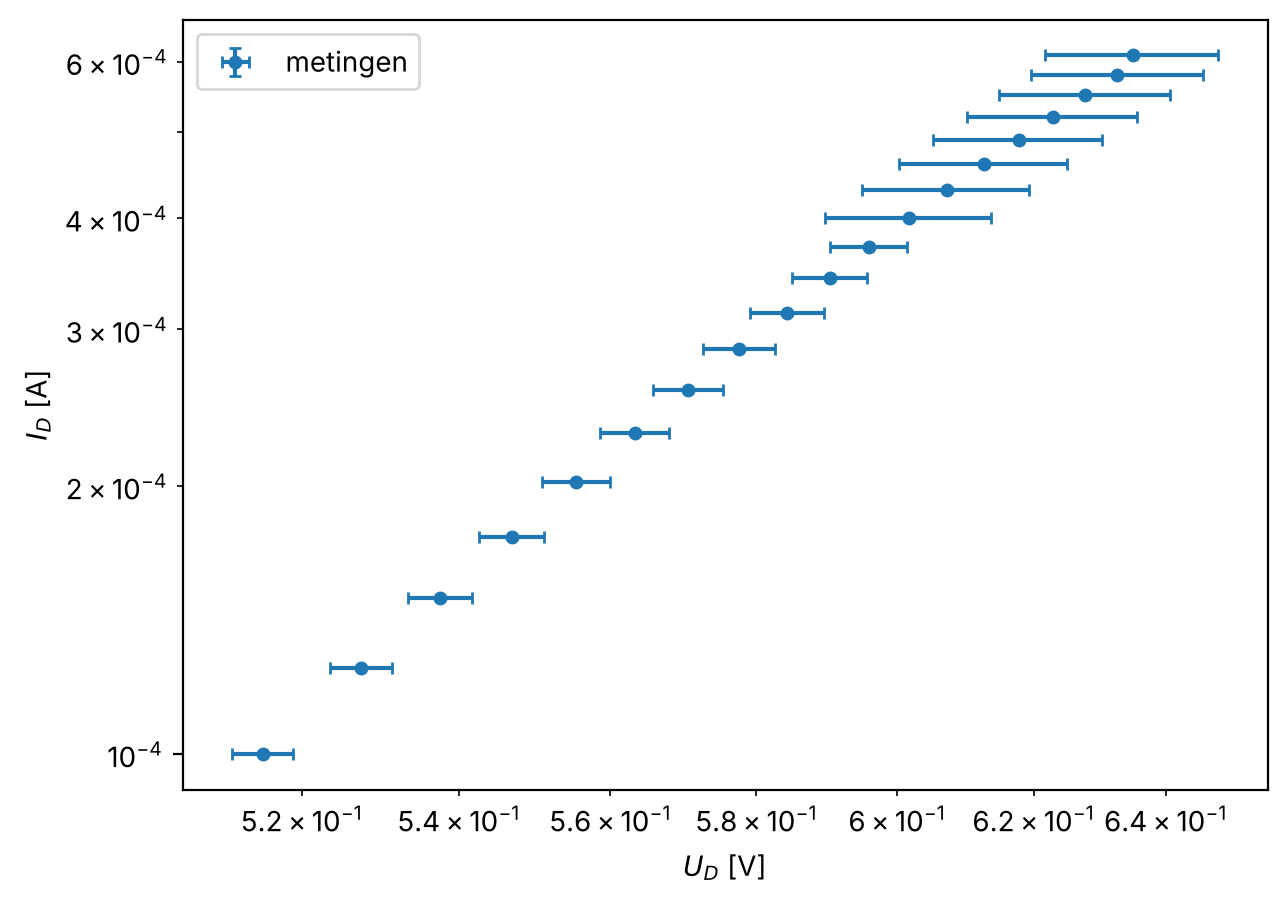

In [5]:
plt.figure(figsize=(7, 5))
plt.errorbar(U_D, I_D, xerr=u_UD, yerr=u_ID, fmt='o', ms=4, capsize=2, label='metingen')
plt.loglog()
plt.xlabel('$U_D$ [V]')
plt.ylabel('$I_D$ [A]')
plt.legend()
plt.show()



b  = 15.62 ± 0.04 1/V
I0 = 3.34e-08 A


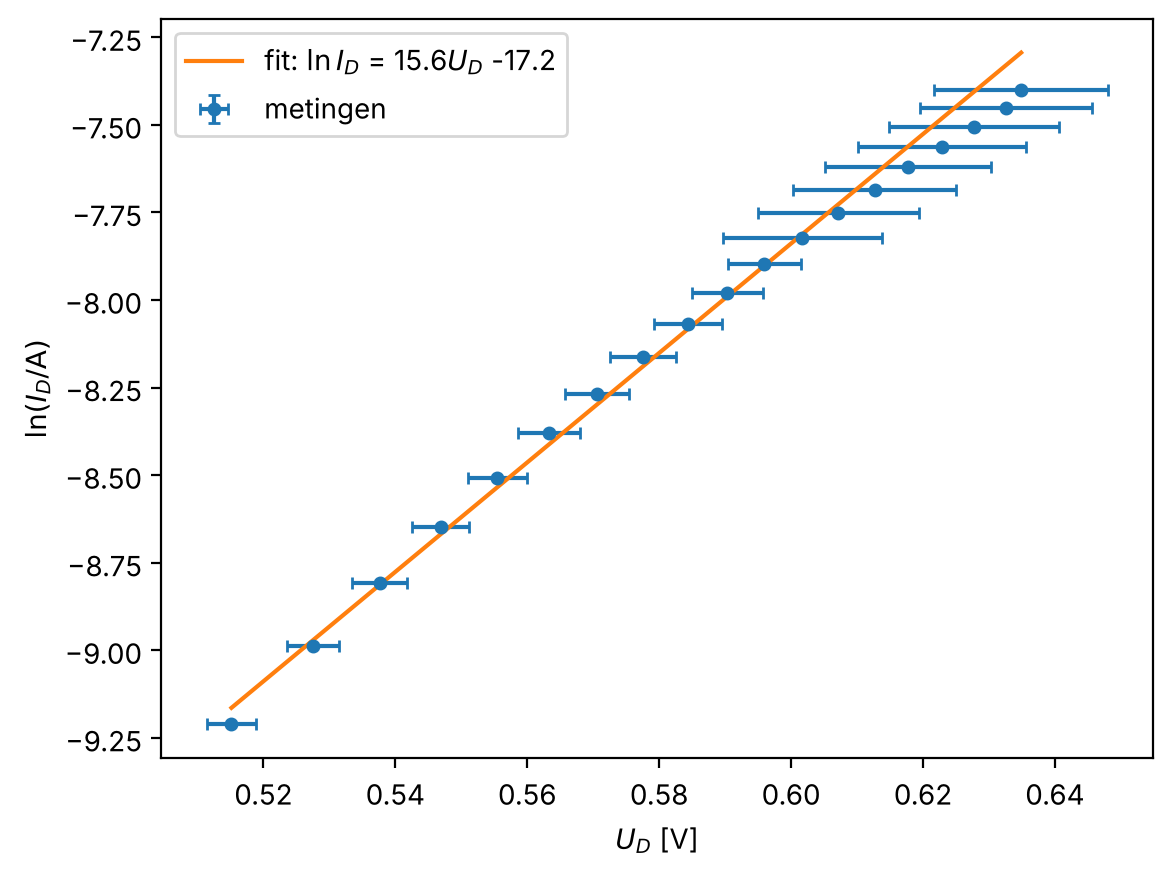

In [6]:
# Fit van een rechte lijn: ln(I_D) = b*U_D + ln(I0)
x = U_D
y = np.log(I_D)


(b, lnI0), cov = curve_fit(lijn, x, y, sigma= u_UD, absolute_sigma=True)
u_b, u_lnI0 = np.sqrt(np.diag(cov))


print(f"b  = {b:.2f} ± {u_b:.2f} 1/V")
print(f"I0 = {np.exp(lnI0):.2e} A")

# Plot: ln(I_D) tegen U_D met de gefitte rechte lijn
xx = np.linspace(x.min(), x.max(), 1000)
plt.figure()
plt.errorbar(x, y, xerr=u_UD, yerr=u_ID/I_D, fmt='o', ms=4, capsize=2, label='metingen')
plt.plot(xx, lijn(xx, b, lnI0), label=f'fit: $\\ln I_D$ = {b:.1f}$U_D$ {lnI0:+.1f}')
plt.xlabel('$U_D$ [V]')
plt.ylabel('$\\ln(I_D / \\mathrm{A})$')
plt.legend()
plt.show()

**Describing the pattern in the processed data:**  
In de semi-log plot liggen de punten op een rechte lijn. De stroom $I_D$ neemt dus exponentieel toe met $U_D$, zoals de diodevergelijking voorspelt. Over het gebruikte meetgebied verandert $I_D$ met enkele decades.

In [7]:
# Eindresultaat: k_B met onzekerheid
kB = -q/(b*n*T)
u_kB = abs(kB)*np.sqrt((u_b/b)**2 + (u_n/n)**2 + (u_T/T)**2)
kB_tabel = 1.380649e-23
verschil = abs(kB - kB_tabel)/u_kB

print(f"k_B = ({kB:.3e} ± {u_kB:.1e}) J/K")
print(f"tabelwaarde = {kB_tabel:.6e} J/K, verschil = {verschil:.1f} x onzekerheid")

k_B = (1.749e-23 ± 8.8e-25) J/K
tabelwaarde = 1.380649e-23 J/K, verschil = 4.2 x onzekerheid


**Notes:**  

# Discussion

In [8]:
# Controle 1: fit opnieuw met de juiste onzekerheid in ln(I_D), u_tot (zie Processing)
u_tot = np.sqrt((u_ID/I_D)**2 + (b*u_UD)**2)
(b_c, lnI0_c), cov_c = curve_fit(lijn, U_D, np.log(I_D), sigma=u_tot, absolute_sigma=True)
u_b_c = np.sqrt(cov_c[0, 0])
kB_c = -q/(b_c*n*T)
u_kB_c = abs(kB_c)*np.sqrt((u_b_c/b_c)**2 + (u_n/n)**2 + (u_T/T)**2)
chi2red_c = np.sum(((np.log(I_D) - lijn(U_D, b_c, lnI0_c))/u_tot)**2)/(len(U_D) - 2)
print(f"Juiste sigma:  b = {b_c:.1f} ± {u_b_c:.1f} 1/V, k_B = ({kB_c:.2e} ± {u_kB_c:.1e}) J/K, "
      f"verschil = {abs(kB_c-kB_tabel)/u_kB_c:.1f} x onzekerheid, chi2_red = {chi2red_c:.2f}")

# Controle 2: belasting van de deler R2/R3 door de diodetak (Thevenin)
# De diodestroom loopt ook door R2 // R3, daardoor is de spanning over de diodetak lager dan U_bron*R3/(R2+R3)
R_th = R2*R3/(R2 + R3)
U_D_corr = U_bron*deler - I_D*R_th - U_R1
print(f"R_th = {R_th:.1f} Ohm, fout in U_D loopt op van {1e3*I_D[0]*R_th:.0f} tot {1e3*I_D[-1]*R_th:.0f} mV")
print(f"R1 + R_D loopt van {R1 + U_D[0]/I_D[0]:.0f} tot {R1 + U_D[-1]/I_D[-1]:.0f} Ohm (R3 = {R3:.0f} Ohm)")

u_tot2 = np.sqrt((u_ID/I_D)**2 + (b_c*u_UD)**2)
(b_k, lnI0_k), cov_k = curve_fit(lijn, U_D_corr, np.log(I_D), sigma=u_tot2, absolute_sigma=True)
u_tot2 = np.sqrt((u_ID/I_D)**2 + (b_k*u_UD)**2)   # nog een keer met de nieuwe b
(b_k, lnI0_k), cov_k = curve_fit(lijn, U_D_corr, np.log(I_D), sigma=u_tot2, absolute_sigma=True)
u_b_k = np.sqrt(cov_k[0, 0])
kB_k = -q/(b_k*n*T)
u_kB_k = abs(kB_k)*np.sqrt((u_b_k/b_k)**2 + (u_n/n)**2 + (u_T/T)**2)
print(f"Gecorrigeerd:  b = {b_k:.1f} ± {u_b_k:.1f} 1/V, k_B = ({kB_k:.2e} ± {u_kB_k:.1e}) J/K, "
      f"verschil = {abs(kB_k-kB_tabel)/u_kB_k:.1f} x onzekerheid")
print(f"n die bij de tabelwaarde van k_B hoort: {-q/(b_k*kB_tabel*T):.2f}")

Juiste sigma:  b = 15.6 ± 0.7 1/V, k_B = (1.75e-23 ± 1.2e-24) J/K, verschil = 3.2 x onzekerheid, chi2_red = 0.16
R_th = 76.7 Ohm, fout in U_D loopt op van 8 tot 47 mV
R1 + R_D loopt van 6155 tot 2037 Ohm (R3 = 100 Ohm)
Gecorrigeerd:  b = 21.9 ± 1.3 1/V, k_B = (1.25e-23 ± 9.8e-25) J/K, verschil = 1.4 x onzekerheid
n die bij de tabelwaarde van k_B hoort: 1.81


**Resultaat.** We vinden $k_B = (1{,}75 \pm 0{,}09)\cdot10^{-23}\,\mathrm{J/K}$. Dat is 27 % hoger dan de tabelwaarde en wijkt 4,2 keer de onzekerheid af. Er zit dus een systematische fout in de meting of de verwerking. Wel klopt het verwachte patroon: in de semi-log plot liggen de punten op een rechte lijn, dus $I_D$ groeit exponentieel met $U_D$.

**Belangrijkste oorzaak: de deler $R_2$/$R_3$ wordt belast.** In opdracht 5 hebben we aangenomen dat $R_3 \ll R_1 + R_D$. Dat klopt hier niet goed genoeg. $R_1 + R_D$ loopt van ongeveer $6{,}2\,\mathrm{k\Omega}$ tot $2{,}0\,\mathrm{k\Omega}$. Dat is maar 20 tot 60 keer zo groot als $R_3 = 100\,\Omega$. De diodestroom (0,1 tot 0,6 mA) loopt ook door de Thévenin-weerstand van de deler, $R_2 /\!/ R_3 = 76{,}7\,\Omega$. Daardoor is de echte spanning over de diodetak 8 tot 47 mV lager dan $\frac{R_3}{R_2+R_3}U_{bron}$. Die fout is groter dan $u(U_D)$, en hij wordt groter naarmate de stroom stijgt. Daardoor wordt de $U_D$-as uitgerekt en komt de helling $b$ te laag uit, zodat $k_B$ te hoog uitkomt. Na correctie (controle 2 hierboven) vinden we $b = 21{,}9 \pm 1{,}3\,\mathrm{V^{-1}}$ en $k_B = (1{,}25 \pm 0{,}10)\cdot10^{-23}\,\mathrm{J/K}$. Die waarde ligt maar 1,4 keer de onzekerheid van de tabelwaarde af.

**Idealiteitsfactor $n$.** $n$ en $k_B$ komen alleen samen voor in de helling ($b = -q/(n k_B T)$). Met deze meting bepalen we dus eigenlijk $n\,k_B$. Voor $n = 2{,}0 \pm 0{,}1$ hebben we de waarde uit de opdrachttekst genomen. Die is niet voor deze diode gemeten. Als je de tabelwaarde van $k_B$ invult, volgt na correctie $n = 1{,}81$. Dat past bij een siliciumdiode ($1 \le n \le 2$). De onzekerheid in $n$ (5 %) is zelf al even groot als de gewenste nauwkeurigheid. Dat doel van 5 % was dus niet haalbaar zolang $n$ niet beter bekend is.

**Onzekerheid van de fit.** In de fit (cel met `curve_fit`) staat `sigma=u_UD` in plaats van $u_{tot}$ uit de Processing-sectie. Daardoor is $u(b)$ ongeveer 15 keer te klein: $0{,}04$ in plaats van $0{,}67\,\mathrm{V^{-1}}$. Met de juiste sigma wordt $u(k_B) = 1{,}2\cdot10^{-24}\,\mathrm{J/K}$. Het verschil met de tabelwaarde is dan nog 3,2 keer de onzekerheid, dus de conclusie dat er een systematische fout is blijft staan. $\chi^2_{red} = 0{,}16$ is veel kleiner dan 1. De onzekerheden zijn dus te groot geschat. Dat komt waarschijnlijk doordat we de DMM-specificaties achteraf hebben geschat. Bovendien is een ijkfout van de meter voor alle punten dezelfde (systematisch) en niet willekeurig per punt.

**Overige punten.**
- Het meetgebied is klein: $I_D$ gaat van 0,1 tot 0,6 mA, dus minder dan één decade. Met een groter stroombereik kun je de helling nauwkeuriger bepalen.
- Vanaf punt 12 springt de 3¾-digit meter naar het 40 V-bereik. Daardoor wordt $u(U_D)$ ongeveer 2,5 keer zo groot (van ca. 5 naar 12 mV).
- De temperatuur hebben we niet gemeten; we hebben 20 °C aangenomen. Een fout van 1 K geeft maar 0,3 % in $k_B$. De diode warmt zelf nauwelijks op ($P < 0{,}4\,\mathrm{mW}$). Temperatuur is dus geen belangrijke foutbron.

# Conclusion

Uit de $(I,V)$-karakteristiek van de siliciumdiode volgt $k_B = (1{,}75 \pm 0{,}09)\cdot10^{-23}\,\mathrm{J/K}$. De stroom neemt zoals verwacht exponentieel toe met de spanning. Toch wijkt $k_B$ 4,2 keer de onzekerheid af van de tabelwaarde $1{,}380649\cdot10^{-23}\,\mathrm{J/K}$, dus de hypothese wordt niet bevestigd. De belangrijkste oorzaak is dat de diodetak de spanningsdeler $R_2$/$R_3$ belast. Als we daarvoor corrigeren, vinden we $k_B = (1{,}25 \pm 0{,}10)\cdot10^{-23}\,\mathrm{J/K}$. Dat komt binnen 1,4 keer de onzekerheid overeen met de tabelwaarde. De gewenste nauwkeurigheid van 5 % hebben we niet gehaald, vooral door de onzekerheid in de idealiteitsfactor $n$.

**Verbeteringen:**
- **Betere weerstanden kiezen.** $R_3$ moet veel kleiner zijn dan $R_1 + R_D$, minstens een factor 1000 in plaats van 20 tot 60. Dat kan met een kleinere $R_3$ en $R_2$, zoals $10\,\Omega$ en $33\,\Omega$ (let dan wel op het vermogen), of met een grotere $R_1$, zoals $10$ tot $100\,\mathrm{k\Omega}$. Een grotere $R_1$ maakt de diodestroom kleiner. Dan meet je ook kleinere stromen, dus over meer decades.
- Meet de spanning over de diodetak (of over de diode zelf) direct met de 5½-digit meter, in plaats van die uit $U_{bron}$ en de deler te berekenen.
- Bepaal $n$ voor deze diode apart (of zoek die op in de datasheet), en meet de temperatuur.
- Gebruik in de fit de juiste onzekerheid $u_{tot}$ en noteer tijdens de meting de echte DMM-specificaties.

# Additional notes, remarks, explanations, thoughts etc